# Seaborn ile Doğrusal Regresyon

🚀 Seaborn kullanarak Doğrusal Regresyon analizine görsel olarak başlayalım!

Hedefimiz aşağıdakilerin ilk anlayışını elde etmektir:
- `orders` özelikleri ve
- onlarla ilişkili `review_scores`

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Import Modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

⚠️ Devam etmeden önce:
* 💾 Önceki ünitenin Orders challenge'ının çözümünü indirin
* 👥 `order_solution.py` dosyasının içeriğini `olist/order.py` dosyanıza kopyala-yapıştır yapın

⚠️ `olist` deponuzda `order.py` dosyasındaki kod değişikliklerini commit etmeyi unutmayın!

👇 Öncelikle `orders` veri setini içeri aktarın

In [4]:
import sys
from pathlib import Path

olist_proje = Path.home() / "Desktop" / "workıntech" / "op" / "data-orders"

if str(olist_proje) not in sys.path:
    sys.path.insert(0, str(olist_proje))

from olist.order import Order

orders = Order().get_training_data(
    with_distance_seller_customer=False
)

print("Veri boyutu:", orders.shape)
display(orders.head())

Veri boyutu: (96353, 12)


,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0,0,4,1,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0,0,4,1,1,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1,0,5,1,1,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1,0,5,1,1,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1,0,5,1,1,19.90,8.72


## 1 - Özellik Korelasyonunu İnceleme

❓Özellikler arasındaki çeşitli korelasyonları inceleyin: hangi özellik `review_score` ile en çok korelasyonlu görünüyor?

<details>
    <summary>▸ İpucu</summary>

* `DataFrame.corr(numeric_only=True)` kullanın `sns.heatmap()` ve `cmap='coolwarm'` ile kombinasyon yaparak
* `review_score` ile her bir özellik arasındaki korelasyon katsayılarının mutlak değerlerine bakın,
    * katsayı ne kadar yüksekse, verilen özellik `review_score` ile o kadar çok korelasyonludur (pozitif veya negatif)

</details>

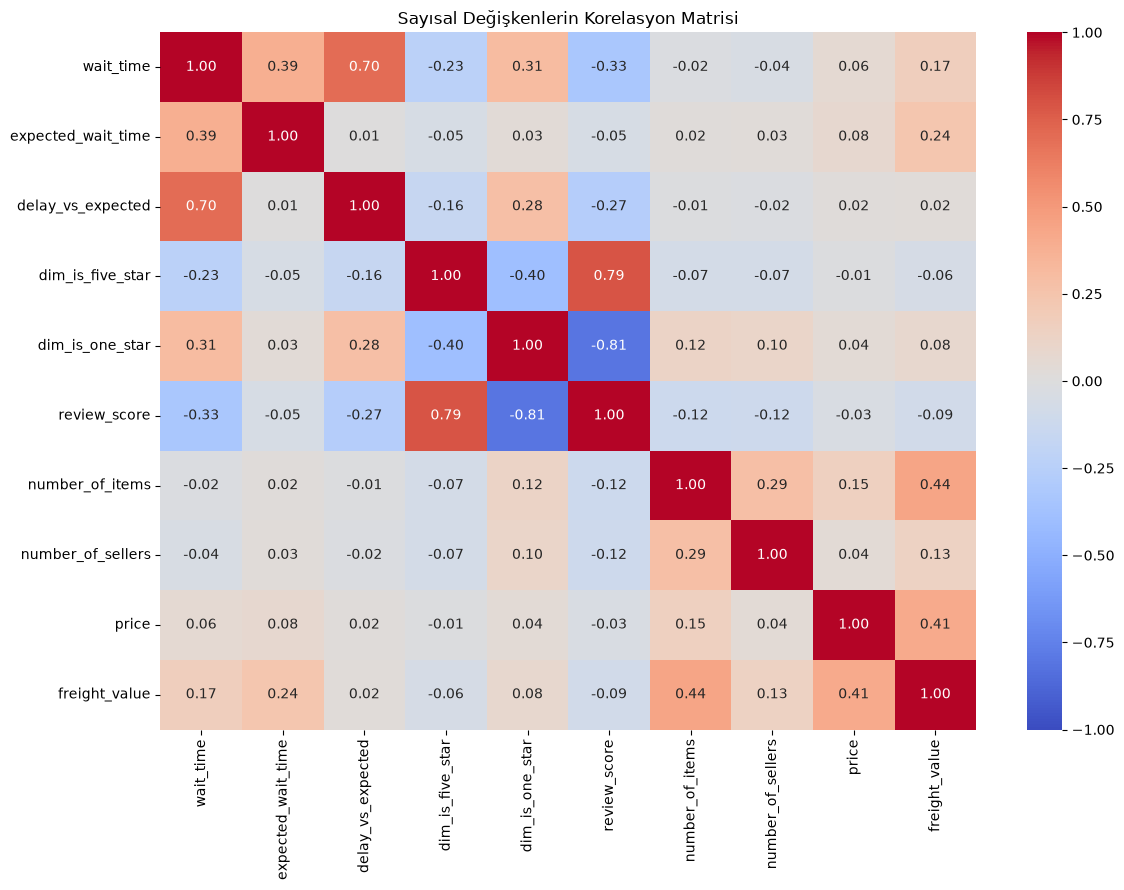

,review_score_korelasyonu
wait_time,-0.333758
delay_vs_expected,-0.272281
number_of_items,-0.123492
number_of_sellers,-0.116942
freight_value,-0.090013
expected_wait_time,-0.052410
price,-0.034742


En güçlü ilişkili iki değişken:


wait_time           -0.333758
delay_vs_expected   -0.272281
Name: review_score, dtype: float64

In [5]:
corr = orders.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Sayısal Değişkenlerin Korelasyon Matrisi")
plt.tight_layout()
plt.show()

# Puanın kendisini ve puandan türetilmiş göstergeleri dışarıda bırak.
puan_korelasyonlari = (
    corr["review_score"]
    .drop(
        ["review_score", "dim_is_one_star", "dim_is_five_star"],
        errors="ignore"
    )
    .dropna()
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(puan_korelasyonlari.to_frame("review_score_korelasyonu"))
print("En güçlü ilişkili iki değişken:")
display(puan_korelasyonlari.head(2))

* 😏 _Kaptan Açık :_
    * `review_score` kendisiyle %100 korelasyonludur
    * ve `dim_is_one_star` ve `dim_is_five_star` ile güçlü korelasyonludur...
* ⚠️ `review_score` ile ilgili sonraki iki en yüksek korelasyon katsayısı :
    * `wait_time` : - %34
    * `delay_vs_expected` : - %27

## 2. `review_score` ile teslimat süresi arasında Doğrusal Regresyon

👉 Görünüşe göre `review_score` çoğunlukla `wait_time` (= - %34) ve `delay_vs_expected` (- %27) ile korelasyonludur.

🎨 Bu korelasyonları `seaborn` ile araştıralım

### 2.1 Grafikler
❓ Sırasıyla `review_score` ile `wait_time` ve `delay_vs_expected` arasında regresyon yapan 2 grafik oluşturun.

<u>İpuçları</u>:

- Hız açısından veri çerçevesini rastgele bir `10.000 satırlık örneğe` indirin (veri keşiflemede iyi bir uygulama)
- Gerekirse her yürütmede örneği değiştirilmekten kaçınmak için `DataFrame.sample()` sabit bir `random_state` ile kullanın
- Regresyon `lines` çizmek için `sns.regplot()` kullanın
- Saçılım grafiğinin yoğunluğunu daha iyi görselleştirmek için bazı `y_jitter` parametreleri ekleyin
- `sns.regplot()` hemen sonrasına bunu ekleyerek `xlim` ve `ylim` sınırlayın (aynı hücrede):
  ```python
  plt.xlim(right=70)
  plt.ylim(bottom=0)
  ```

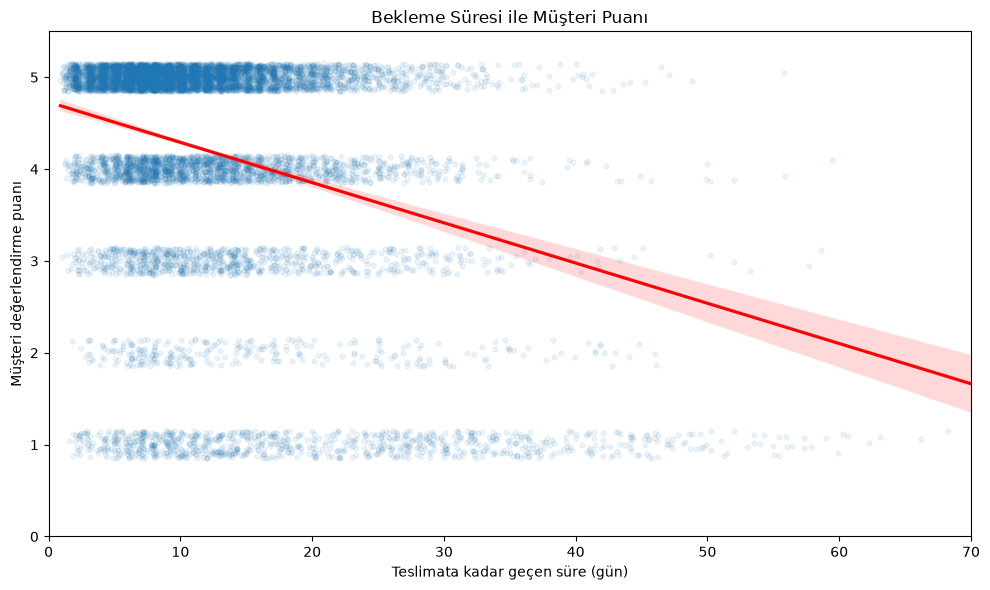

In [6]:
analiz = orders[
    ["review_score", "wait_time", "delay_vs_expected"]
].dropna()

ornek = analiz.sample(
    n=min(10_000, len(analiz)),
    random_state=42
)

plt.figure(figsize=(10, 6))
sns.regplot(
    data=ornek,
    x="wait_time",
    y="review_score",
    y_jitter=0.15,
    ci=95,
    seed=42,
    scatter_kws={"alpha": 0.08, "s": 12},
    line_kws={"color": "red"}
)
plt.xlim(left=0, right=70)
plt.ylim(bottom=0, top=5.5)
plt.xlabel("Teslimata kadar geçen süre (gün)")
plt.ylabel("Müşteri değerlendirme puanı")
plt.title("Bekleme Süresi ile Müşteri Puanı")
plt.tight_layout()
plt.show()

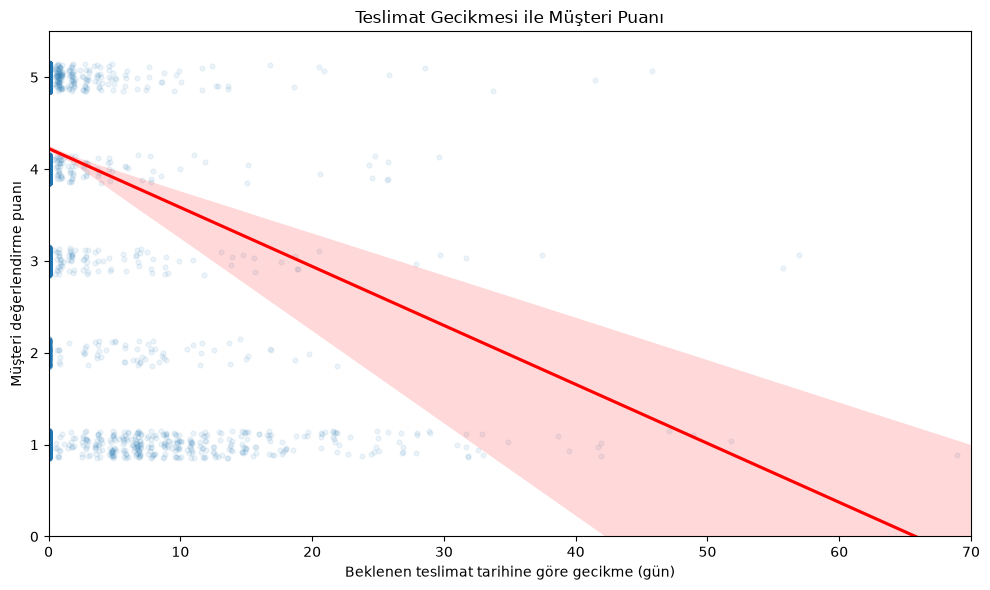

In [7]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=ornek,
    x="delay_vs_expected",
    y="review_score",
    y_jitter=0.15,
    ci=95,
    seed=42,
    scatter_kws={"alpha": 0.08, "s": 12},
    line_kws={"color": "red"}
)
plt.xlim(left=0, right=70)
plt.ylim(bottom=0, top=5.5)
plt.xlabel("Beklenen teslimat tarihine göre gecikme (gün)")
plt.ylabel("Müşteri değerlendirme puanı")
plt.title("Teslimat Gecikmesi ile Müşteri Puanı")
plt.tight_layout()
plt.show()

ℹ️ `regplot` ne yaptı ? 

👉 `review_score` ile `wait_time` ve `delay_vs_exp` arasında `Doğrusal Regresyon` yapmaya çalıştı

🧐 Pek yorumlanabilir görünmüyor, değil mi ?

👉 Haklısınız: sadece 5 farklı review skoru vardır ve bunlar beş farklı olası değeri olan kategorisel bir değişken olarak yorumlanabilir (örneğin: "çok kötü", "kötü", "orta", "iyi" ve "çok iyi") ve `wait_time` ve `delay_vs_exp` olan iki sürekli değere karşı regresyon yapmaya çalışıyoruz.

👀 Ancak regresyon çizgilerine göre çok sezgisel bir desen görebiliriz: bekleme süresi ve/veya gecikme ne kadar uzunsa, review skoru o kadar düşüktür - şaşırtıcı değil. Ama review skoru ne kadar hızlı düşüyor ?

### 2.2 Yorumlama

❓Her eğrinin `eğimini` görsel olarak "hesaplamaya" çalışın. 

✍️ Bu katsayıları veri eğitimi almamış bir kitleye açıklamış olsaydınız, bunları nasıl yorumlayacağınızı yazın.

<details>
    <summary>Cevap</summary>

- `Slope wait_time ≈ -0.05` : "Bir sipariş teslim edilmesi için beklenen her ek gün için, review skoru ortalama olarak 0.05 azalır"
- `Slope delay ≈ -0.1` : "Bir sipariş _beklenen teslimat tarihinden sonra_ teslim edilmesi için her ek gün, review skoru ortalama olarak 0.1 azalır"

❓ Gecikmenin bekleme süresinden daha etkileyici görünmesine şaşırdınız mı? 

👉 Siparişinizi almak için sabırsız olabilirsiniz ve kısa bir bekleme süresi istersiniz, ancak paketinizi beklenen teslimat tarihinden sonra almaktan daha da hayal kırıklığına uğrarsınız!

</details>

In [8]:
egimler = {}

for degisken in ["wait_time", "delay_vs_expected"]:
    egim, sabit = np.polyfit(
        ornek[degisken],
        ornek["review_score"],
        deg=1
    )
    egimler[degisken] = egim

    yon = "azalış" if egim < 0 else "artış"

    print(
        f"{degisken}: Her ek gün, tahmin edilen ortalama "
        f"müşteri puanında {abs(egim):.3f} puanlık "
        f"{yon} ile ilişkilidir."
    )

wait_time: Her ek gün, tahmin edilen ortalama müşteri puanında 0.044 puanlık azalış ile ilişkilidir.
delay_vs_expected: Her ek gün, tahmin edilen ortalama müşteri puanında 0.064 puanlık azalış ile ilişkilidir.


Bekleme süresi ve teslimat gecikmesi için negatif eğim, süre
arttıkça tahmin edilen ortalama müşteri puanının düştüğünü gösterir.
Eğimin mutlak değeri, bir günlük artışla ilişkili puan değişimidir.

Bu iki model değişkenleri ayrı ayrı inceler; diğer faktörleri
sabit tutmaz. Bu nedenle sonuçlar tek başına nedensellik göstermez.
Ürün kategorisi, bölge, fiyat ve satıcı performansı hem teslimat
süresiyle hem de müşteri puanıyla ilişkili olabilir.

Puanlar 1–5 aralığında olduğundan doğrusal regresyon burada
genel eğilimi özetlemek için kullanılmıştır. Özellikle uç sürelerde
tahminler bu aralığın dışına çıkabilir.


### 2.3 Çıkarımsal Analiz

Bu regplotlar için 100.000 siparişin tamamını kullansak bile, bu siparişler sonuçta sadece 16 ayın verilerini temsil eder...

⚠️⚠️⚠️ Bu katsayıların **istatistiksel olarak anlamlı** olduğundan **ne kadar emin** olduğumuz? ⚠️⚠️⚠️

⚡️ Bu katsayıların istatistiksel anlamlılığı hakkında sorular:

* Bu katsayılar gelecekteki siparişlere iyi bir şekilde genelleştirilebilir mi (diğer her şey eşit olarak) ? (*İdeal cevap: Evet*) 
* Bu katsayıların sınırlı gözlem döneminden kaynaklanan rastgele dalgalanmalar yakalamadığından emin miyiz ? (*İdeal cevap: Hayır*) 

🧐 Bu iki eğim için ortalama değer etrafında **`güven aralığını`** tahmin etmemiz gerekir  :
$$slope_{wait} = -0.05 ± \ ?? \ \text{[%95 aralık]} $$
$$slope_{delay} = -0.1 ± \ ?? \ \text{[%95 aralık]} $$

⭐️ Neyse ki, `Seaborn` bu %95 güven aralığını regresyon çizgisinin etrafında gölgeli bir mavi koni ile zaten hesaplamıştır!

❓`Seaborn` `regplot` yeniden kullanarak iki güven aralığını görselleştirin:
- Örnek veri setinizin `boyutunu değiştirin`: 
    - Örnek boyutu küçüldükçe eğimin nasıl değiştiğine dikkat edin. 
    - Güven aralığı hakkında ne dersiniz?
- `ci` adlı regplot parametresi ile oynayarak `güven aralığının boyutunu` değiştirin (%95 varsayılan)

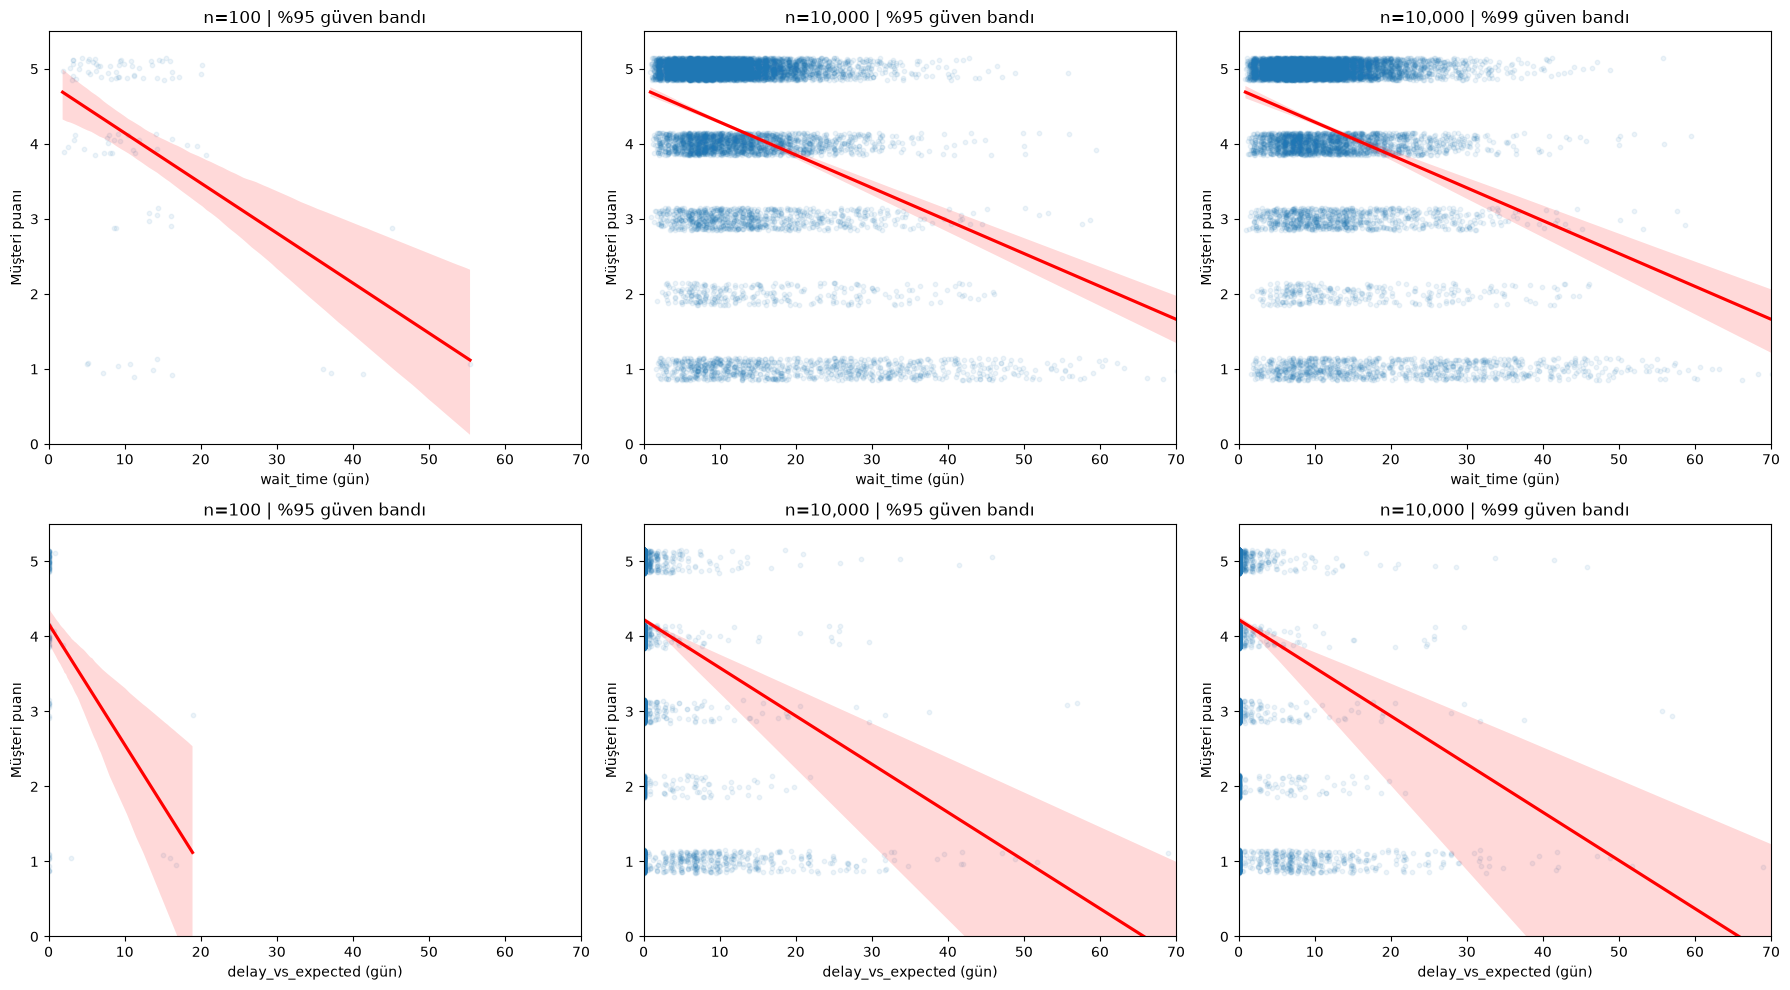

In [9]:
ayarlar = [
    (100, 95),
    (10_000, 95),
    (10_000, 99)
]

degiskenler = ["wait_time", "delay_vs_expected"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for satir, degisken in enumerate(degiskenler):
    for sutun, (n, guven) in enumerate(ayarlar):
        alt_ornek = analiz.sample(
            n=min(n, len(analiz)),
            random_state=42
        )

        ax = axes[satir, sutun]

        sns.regplot(
            data=alt_ornek,
            x=degisken,
            y="review_score",
            ci=guven,
            n_boot=1000,
            seed=42,
            y_jitter=0.15,
            scatter_kws={"alpha": 0.08, "s": 10},
            line_kws={"color": "red"},
            ax=ax
        )

        ax.set(
            title=f"n={len(alt_ornek):,} | %{guven} güven bandı",
            xlabel=f"{degisken} (gün)",
            ylabel="Müşteri puanı",
            xlim=(0, 70),
            ylim=(0, 5.5)
        )

plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import linregress, t

sonuclar = []

for degisken in degiskenler:
    sonuc = linregress(analiz[degisken], analiz["review_score"])

    kritik_t = t.ppf(0.975, df=len(analiz) - 2)
    alt = sonuc.slope - kritik_t * sonuc.stderr
    ust = sonuc.slope + kritik_t * sonuc.stderr

    sonuclar.append({
        "degisken": degisken,
        "egim": sonuc.slope,
        "guven_alt": alt,
        "guven_ust": ust,
        "p_degeri": sonuc.pvalue,
        "sifiri_iceriyor": alt <= 0 <= ust
    })

egim_tablosu = pd.DataFrame(sonuclar).set_index("degisken")
display(egim_tablosu)

for degisken, satir in egim_tablosu.iterrows():
    yorum = (
        "sıfırı içeriyor; %5 düzeyinde anlamlı değil"
        if satir["sifiri_iceriyor"]
        else "sıfırı içermiyor; %5 düzeyinde anlamlı"
    )
    print(f"{degisken}: Eğim için %95 güven aralığı {yorum}.")

,egim,guven_alt,guven_ust,p_degeri,sifiri_iceriyor
degisken,,,,,
wait_time,-0.045349,-0.046158,-0.044540,0.0,False
delay_vs_expected,-0.075137,-0.076814,-0.073461,0.0,False


wait_time: Eğim için %95 güven aralığı sıfırı içermiyor; %5 düzeyinde anlamlı.
delay_vs_expected: Eğim için %95 güven aralığı sıfırı içermiyor; %5 düzeyinde anlamlı.


🔎 Yorumlama:

* **Boş Hipotez** $H_0$ : "bu değişken review skoru etkilemez", yani katsayısı sıfıra eşittir

Tüm veri noktalarımızı çizdiğimizde:
- Eğim için %95 güven aralığı 0 değerini içermez.
    - 👉 `Daha yavaş teslimatların daha zayıf yorumlarla ilişkili olduğundan %95 emin`.
- "Teslimat süresinin review skorları üzerindeki etkisi hemen hemen sıfırdır" boş hipotezi ile ilişkili **`p-değeri`** %5'ten düşüktür
    - 👉 Bu boş hipotezi güvenle reddedebilir ve **`alternatif hipotez`** = `"teslimat süresi review skoru üzerinde etkiye sahiptir"` düşünebiliriz

🔥 Bulguşlarımızın **istatistiksel olarak anlamlı** olduğu söylenir. 

⚠️ Ancak, **korelasyon nedensellik anlamına gelmez**. 

- Belirli ürünlerin teslimatı doğal olarak daha yavaş olabilir (örn. ağır ürünler)
    - Bu ürün kategorileri, teslimat sürelerinin ne kadar uzun olursa olsun, genellikle düşük review_score'a sahip olacaktır. 

👉 **Karıştırıcı faktörleri** tanımlamak çok önemlidir ve basit bir tek değişkenli regresyon ile yapılamaz. 

</details>

### Güven aralıklarının yorumu

- Küçük örneklemlerde eğim tahmini daha değişken ve güven bandı
  genellikle daha geniştir.
- Örneklem büyüdükçe, benzer örnekleme koşullarında belirsizlik
  genellikle azalır ve güven bandı daralır.
- Aynı örneklem için %99 güven bandı, %95 güven bandından geniştir.
- Regplot'un gölgeli alanı ortalama yanıtın güven bandıdır;
  tek bir müşterinin puanı için tahmin aralığı değildir.
- Eğimin %95 güven aralığı sıfırı içermiyorsa, ilgili test
  varsayımları altında sıfır eğim hipotezi %5 düzeyinde reddedilir.
- Hesaplanan klasik eğim aralıkları bağımsız gözlemler ve
  sabit hata varyansı gibi varsayımlara dayanır.
- İstatistiksel anlamlılık nedensellik kanıtı değildir.
  Ürün kategorisi, bölge ve fiyat gibi karıştırıcı faktörler
  daha kapsamlı bir analizde dikkate alınmalıdır.

---
🏁 Tebrikler! 

🙏 Notebook'unuzu `commit` ve `push` etmeyi unutmayın